# Stage 4 : Explainable AI: Grad-CAM, attention rollout and LIME for the final ViT

**Purpose:** explain the final ViT's predictions with three methods, check whether the explanations are trustworthy,
and analyse correct **and** incorrect predictions.

| Method | Type | What it explains |
|---|---|---|
| **Grad-CAM (adapted for ViT)** | architecture-specific, gradient-based | which image patches increase the score of the predicted class |
| **Attention rollout** | architecture-specific, attention-based | which patches the network's attention flows to (not class-specific) |
| **LIME** | model-agnostic, perturbation-based | which image regions (superpixels) change the prediction when hidden |

**Validation checks :**
1. **Deletion test** on 100 validation images: hide the most important patches and see how fast the predicted-class
   probability falls, compared with hiding **random** patches. A trustworthy explanation should cause a faster drop.
2. **Model-randomisation test:** scramble the last layers' weights — a trustworthy explanation should change.
3. **Case studies:** 4 correct and 4 **incorrect** predictions, each with an occlusion test of the highlighted region.
4. **Loss-region focus:** how much of each explanation falls inside the forest-loss polygon.

**Rules:** validation data only (the test set is still untouched). **Run on a T4 GPU** (LIME needs many forward passes).

## 0. Setup, paths and seeds

In [ ]:
import os, sys, json, time, random, hashlib, zipfile, pickle, warnings, io, copy
from pathlib import Path
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED); np.random.seed(SEED)
QUICK = os.environ.get("FN_QUICK") == "1"              # offline testing only — leave unset

IN_COLAB = "google.colab" in sys.modules
if os.environ.get("FORESTNET_BASE"):
    BASE = Path(os.environ["FORESTNET_BASE"])
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/forestnet_project")
elif Path("/kaggle/working").exists():
    BASE = Path("/kaggle/working/forestnet_project")
else:
    BASE = Path("./forestnet_project")
RUNS = BASE / "outputs" / "stage3" / "runs"; CACHE = BASE / "cache"
OUT4 = BASE / "outputs" / "stage4"; OUT4.mkdir(parents=True, exist_ok=True)
print("Project folder:", BASE)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/forestnet_project


In [ ]:
!pip -q install timm

import torch, torch.nn as nn, torch.nn.functional as F
import timm
import matplotlib.pyplot as plt
from matplotlib.path import Path as MplPath
from PIL import Image
from scipy.stats import spearmanr
from skimage.segmentation import slic, mark_boundaries
from sklearn.linear_model import Ridge
warnings.filterwarnings("ignore", message="Unpickling a shapely")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

DEV = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)
print("torch", torch.__version__, "| timm", timm.__version__, "| device:", DEV)

torch 2.11.0+cu130 | timm 1.0.30 | device: cuda


## 1. Split, cache and the final ViT
The same frozen split and image cache as Stage 3. The model used for the explanations (and later for the web app) is
the final ViT run with the **highest validation macro-F1** among its three seeds : chosen on validation data only.

In [ ]:
def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

meta = json.load(open(BASE / "outputs" / "dataset_meta.json"))
assert sha256(BASE / "outputs" / "split_manifest.csv") == meta["manifest_sha256"], "Split changed!"
man = pd.read_csv(BASE / "outputs" / "split_manifest.csv").sort_values("example_path").reset_index(drop=True)
CLASSES = sorted(man["merged_label"].unique()); CLS2ID = {c: i for i, c in enumerate(CLASSES)}
SHORT = {"Grassland shrubland": "Grassland", "Other": "Other", "Plantation": "Plantation", "Smallholder agriculture": "Smallholder"}
man["y"] = man["merged_label"].map(CLS2ID)
VA_IDX = np.where(man.split == "val")[0]

cmeta = json.load(open(CACHE / "cache_meta.json"))
assert cmeta["manifest_sha256"] == meta["manifest_sha256"], "Cache is from another split — re-run Stage 3 §3."
COMP = np.load(CACHE / "comp_full.npy")
IMG = COMP.shape[1]; GRID = IMG // 16                     # 224 px -> 14 x 14 patches
print("Cache:", COMP.shape, "| validation events:", len(VA_IDX))

MEAN = torch.tensor(meta["train_rgb_norm"]["mean"]).view(1, 3, 1, 1)
STD = torch.tensor(meta["train_rgb_norm"]["std"]).view(1, 3, 1, 1)
MEAN_U8 = (np.array(meta["train_rgb_norm"]["mean"]) * 255).astype(np.float32)   # "hidden" pixel colour

def to_tensor(imgs_u8):
    """uint8 (N,H,W,3) -> normalised float tensor (N,3,H,W) on the device."""
    x = torch.from_numpy(np.ascontiguousarray(imgs_u8)).permute(0, 3, 1, 2).float() / 255.0
    return ((x - MEAN) / STD).to(DEV)

def stretch(img_u8):
    """Contrast stretch for DISPLAY only (composites are very dark)."""
    lo, hi = np.percentile(img_u8, [2, 98])
    return np.clip((img_u8.astype(np.float32) - lo) / (hi - lo + 1e-6), 0, 1)

Cache: (2757, 224, 224, 3) | validation events: 473


In [ ]:
TIMM_VIT = "vit_small_patch16_224.augreg_in21k_ft_in1k"

class ViTClassifier(nn.Module):           # identical to Stage 3 (weights are loaded, so no download needed)
    def __init__(self, depth=12, n_frozen=3, hidden=256, drop=0.2):
        super().__init__()
        self.backbone = timm.create_model(TIMM_VIT, pretrained=False, num_classes=0)
        self.backbone.blocks = self.backbone.blocks[:depth]
        d = self.backbone.num_features
        self.head = nn.Sequential(nn.LayerNorm(2 * d), nn.Dropout(drop), nn.Linear(2 * d, hidden),
                                  nn.GELU(), nn.Dropout(drop), nn.Linear(hidden, len(CLASSES)))
    def forward(self, x):
        t = self.backbone.forward_features(x)
        return self.head(torch.cat([t[:, 0], t[:, 1:].mean(1)], dim=1))

finals = {f.parent.name: json.load(open(f)) for f in RUNS.glob("S3-VIT-FINAL-s*/result.json")}
RUN_ID = max(finals, key=lambda k: finals[k]["val"]["macro_f1"])
CFG = finals[RUN_ID]["cfg"]
print("Final ViT used for XAI:", RUN_ID, "| val macro-F1", round(finals[RUN_ID]["val"]["macro_f1"], 4))

def load_vit():
    m = ViTClassifier(CFG["depth"], CFG["n_frozen"], CFG["hidden"], CFG["drop"])
    m.load_state_dict(torch.load(RUNS / RUN_ID / "best.pt", map_location="cpu"))
    for blk in m.backbone.blocks:          # use the explicit attention path so attention weights can be read
        blk.attn.fused_attn = False
    return m.to(DEV).eval()

model = load_vit()
json.dump({"run_id": RUN_ID, "cfg": CFG, "val_macro_f1": finals[RUN_ID]["val"]["macro_f1"]},
          open(OUT4 / "xai_model_choice.json", "w"), indent=2, default=str)

@torch.no_grad()
def predict_proba(imgs_u8, m=None, bs=64):
    m = m or model; out = []
    for b in range(0, len(imgs_u8), bs):
        out.append(F.softmax(m(to_tensor(imgs_u8[b:b + bs])), 1).cpu().numpy())
    return np.concatenate(out)

VAL_IMGS = COMP[VA_IDX]
VAL_P = predict_proba(VAL_IMGS); VAL_PRED = VAL_P.argmax(1); VAL_Y = man.y.values[VA_IDX]
print("Recomputed val accuracy:", round((VAL_PRED == VAL_Y).mean(), 4))

Final ViT used for XAI: S3-VIT-FINAL-s43 | val macro-F1 0.7747
Recomputed val accuracy: 0.814


## 2. The three explanation methods

**Grad-CAM for a ViT.** Grad-CAM was designed for CNN feature maps. A ViT has no feature map, but its 196 patch tokens
sit on a 14 × 14 grid, so they can be **reshaped into a 14 × 14 × 384 "feature map"**. So took the tokens entering
the last block's attention (`blocks[-1].norm1`), compute the gradient of the predicted-class score with respect to
them, average the gradient over the 196 positions to get one weight per channel, and sum the weighted channels at each
position . The [CLS] token is dropped. Result: a class-specific 14 × 14 map.

**Attention rollout.** Each block's attention (averaged over its 6 heads, plus the identity for the residual
connection) is multiplied through all 12 blocks to trace how information flows from input patches to the output.
Because the head uses the **[CLS] token and the mean of the patch tokens**, the map is the average of the [CLS] row and
the mean patch row. It is **not class-specific** : it shows where the model looks, not what supports which class.

**LIME.** The image is split into ~50 superpixels (SLIC). 1,000 copies are made with random superpixels hidden
(filled with the training-set mean colour), the model scores each copy, and a weighted linear model estimates how much
each superpixel adds to the predicted-class probability. It only needs predictions, so it works for any model.

In [ ]:
class ViTGradCAM:
    def __init__(self, m):
        self.m = m; self.acts = None; self.grads = None
        self.h = m.backbone.blocks[-1].norm1.register_forward_hook(self._hook)
    def _hook(self, mod, inp, out):
        self.acts = out
        if out.requires_grad:                       # only during Grad-CAM's own (gradient-enabled) pass
            out.register_hook(lambda g: setattr(self, "grads", g))
    def __call__(self, imgs_u8, target=None):
        x = to_tensor(imgs_u8)
        with torch.enable_grad():
            self.m.zero_grad(set_to_none=True)
            logits = self.m(x)
            tgt = logits.argmax(1) if target is None else torch.as_tensor(target, device=DEV)
            logits.gather(1, tgt.view(-1, 1)).sum().backward()
        A, G = self.acts[:, 1:, :].detach(), self.grads[:, 1:, :]          # drop [CLS]: (B, 196, 384)
        cam = F.relu((G.mean(1, keepdim=True) * A).sum(-1)).view(-1, GRID, GRID)
        cam = cam / (cam.amax(dim=(1, 2), keepdim=True) + 1e-8)
        return cam.cpu().numpy()

class AttentionRollout:
    def __init__(self, m):
        self.m = m; self.maps = []; self.active = False
        self.hs = [blk.attn.attn_drop.register_forward_hook(self._hook) for blk in m.backbone.blocks]
    def _hook(self, mod, i, o):
        if self.active:                             # record only during rollout's own pass (saves memory)
            self.maps.append(o.detach())
    @torch.no_grad()
    def __call__(self, imgs_u8):
        self.maps.clear(); self.active = True
        self.m(to_tensor(imgs_u8)); self.active = False
        n = self.maps[0].shape[-1]; eye = torch.eye(n, device=DEV)
        R = eye.expand(self.maps[0].shape[0], n, n).clone()
        for A in self.maps:
            A = A.mean(1) + eye                                              # average heads + residual
            A = A / A.sum(-1, keepdim=True)
            R = A @ R
        r = 0.5 * (R[:, 0, 1:] + R[:, 1:, 1:].mean(1))                      # [CLS] row + mean patch row (matches our head)
        r = r.view(-1, GRID, GRID)
        r = (r - r.amin(dim=(1, 2), keepdim=True)) / (r.amax(dim=(1, 2), keepdim=True) - r.amin(dim=(1, 2), keepdim=True) + 1e-8)
        return r.cpu().numpy()

def lime_explain(img_u8, target, m=None, n_samples=1000, n_segments=50, seed=SEED):
    rng = np.random.default_rng(seed)
    segs = slic(stretch(img_u8), n_segments=n_segments, compactness=10, start_label=0)
    S = segs.max() + 1
    Z = rng.integers(0, 2, size=(n_samples, S)); Z[0] = 1                    # first sample = original image
    imgs = np.repeat(img_u8[None], n_samples, 0)
    hidden = Z[:, segs] == 0                                                 # (n, H, W): pixels whose superpixel is off
    imgs[hidden] = MEAN_U8.astype(np.uint8)                                  # hide them with the mean colour
    p = predict_proba(imgs, m)[:, target]
    dist = 1 - Z.sum(1) / S                                                  # share of image hidden
    w = np.exp(-(dist ** 2) / 0.25 ** 2)
    coef = Ridge(alpha=1.0).fit(Z, p, sample_weight=w).coef_
    pix = coef[segs]
    patch = pix.reshape(GRID, 16, GRID, 16).mean((1, 3))                    # to the same 14 x 14 grid
    patch = np.clip(patch, 0, None); patch = patch / (patch.max() + 1e-8)
    return patch, pix, segs

gradcam, rollout = ViTGradCAM(model), AttentionRollout(model)

## 3. Computational cost of each method (milliseconds per image)

In [ ]:
def timed(fn, n=10):
    ts = []
    for i in range(n):
        if DEV == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter(); fn(i)
        if DEV == "cuda": torch.cuda.synchronize()
        ts.append((time.perf_counter() - t0) * 1000)
    return float(np.median(ts[1:]))

n_t = 3 if QUICK else 10
cost = {"Grad-CAM": timed(lambda i: gradcam(VAL_IMGS[i:i + 1]), n_t),
        "Attention rollout": timed(lambda i: rollout(VAL_IMGS[i:i + 1]), n_t),
        "LIME (1,000 samples)": timed(lambda i: lime_explain(VAL_IMGS[i], VAL_PRED[i],
                                                              n_samples=100 if QUICK else 1000), 3 if QUICK else 5),
        "Prediction only": timed(lambda i: predict_proba(VAL_IMGS[i:i + 1]), n_t)}
cost_df = pd.Series(cost, name="ms per image").round(1); display(cost_df); cost_df.to_csv(OUT4 / "xai_cost.csv")

,ms per image
Grad-CAM,27.1
Attention rollout,10.3
"LIME (1,000 samples)",6551.4
Prediction only,11.8


## 4. Sanity check 1 : deletion test (faithfulness)
For each image, patches are hidden in order of importance (most important first) and the probability of the
originally predicted class is recorded after hiding 0, 5, 10, 20, 30 and 50 % of the image. The **area under this
curve** summarises it: **lower = the explanation found the patches the model really depends on**. The same is done with
a **random** patch order (5 random orders averaged) as the reference. 100 validation images for Grad-CAM and rollout;
30 for LIME (it is ~100× slower).

Deletion test took 226s


,n images,AUC mean (lower = better),AUC sd,prob. after hiding 10%,prob. after hiding 20%
Grad-CAM,100.0,0.739,0.345,0.805,0.756
Attention rollout,100.0,0.823,0.280,0.864,0.835
LIME,30.0,0.636,0.314,0.826,0.658
Random,100.0,0.901,0.178,0.926,0.913
Random (LIME subset),30.0,0.888,0.176,0.920,0.912


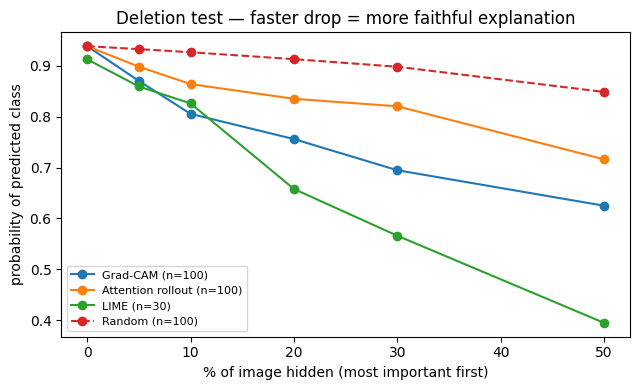

In [ ]:
FRACS = [0.0, 0.05, 0.10, 0.20, 0.30, 0.50]

def hide_patches(img_u8, order, frac):
    k = int(round(frac * GRID * GRID)); out = img_u8.astype(np.float32).copy()
    for p in order[:k]:
        r, c = divmod(int(p), GRID); out[r * 16:(r + 1) * 16, c * 16:(c + 1) * 16] = MEAN_U8
    return out.astype(np.uint8)

def deletion_curve(img_u8, imp, target):
    order = np.argsort(-imp.ravel())
    batch = np.stack([hide_patches(img_u8, order, f) for f in FRACS])
    return predict_proba(batch)[:, target]

def random_curve(img_u8, target, rng, n=5):
    return np.mean([deletion_curve(img_u8, rng.random(GRID * GRID), target) for _ in range(n)], 0)

rng = np.random.default_rng(SEED)
N_FAITH, N_LIME = (6, 3) if QUICK else (100, 30)
sample = rng.choice(len(VA_IDX), N_FAITH, replace=False)
curves = {"Grad-CAM": [], "Attention rollout": [], "LIME": [], "Random": [], "Random (LIME subset)": []}
t0 = time.time()
for j, i in enumerate(sample):
    img, tgt = VAL_IMGS[i], VAL_PRED[i]
    curves["Grad-CAM"].append(deletion_curve(img, gradcam(img[None])[0], tgt))
    curves["Attention rollout"].append(deletion_curve(img, rollout(img[None])[0], tgt))
    rc = random_curve(img, tgt, rng); curves["Random"].append(rc)
    if j < N_LIME:
        curves["LIME"].append(deletion_curve(img, lime_explain(img, tgt, n_samples=100 if QUICK else 1000)[0], tgt))
        curves["Random (LIME subset)"].append(rc)
print(f"Deletion test took {time.time() - t0:.0f}s")

_trap = getattr(np, "trapezoid", None) or np.trapz
auc = lambda c: _trap(c, FRACS) / FRACS[-1]
faith = pd.DataFrame({k: {"n images": len(v), "AUC mean (lower = better)": np.mean([auc(c) for c in v]),
                          "AUC sd": np.std([auc(c) for c in v]),
                          "prob. after hiding 10%": np.mean([c[2] for c in v]),
                          "prob. after hiding 20%": np.mean([c[3] for c in v])}
                      for k, v in curves.items() if len(v)}).T.round(3)
display(faith); faith.to_csv(OUT4 / "xai_deletion_test.csv")

plt.figure(figsize=(6.5, 4))
for k, v in curves.items():
    if len(v) and k != "Random (LIME subset)":
        plt.plot(np.array(FRACS) * 100, np.mean(v, 0), marker="o", label=f"{k} (n={len(v)})", ls="--" if k == "Random" else "-")
plt.xlabel("% of image hidden (most important first)"); plt.ylabel("probability of predicted class")
plt.title("Deletion test — faster drop = more faithful explanation"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT4 / "deletion_curves.png", dpi=150); plt.show()

## 5. Sanity check 2 : model-randomisation test
Following the idea of Adebayo et al. (2018): if an explanation stays the same after the model's learned weights are
destroyed, it is explaining the image, not the model.  **Re-initialise the head and the last 3 transformer blocks**
with random weights and compare the explanation maps before and after (Spearman rank correlation over the 196 patches).
**Low correlation = the explanation depends on what the model learned.**

In [ ]:
rand_model = load_vit()
torch.manual_seed(SEED)
for mod in [*rand_model.backbone.blocks[-3:], rand_model.head]:
    for layer in mod.modules():
        if isinstance(layer, (nn.Linear, nn.LayerNorm)):
            layer.reset_parameters()
gc_rand, ro_rand = ViTGradCAM(rand_model), AttentionRollout(rand_model)
N_RAND = 4 if QUICK else 20
rows = []
for i in sample[:N_RAND]:
    img = VAL_IMGS[i][None]
    rows.append({"Grad-CAM": spearmanr(gradcam(img, [VAL_PRED[i]])[0].ravel(), gc_rand(img, [VAL_PRED[i]])[0].ravel()).correlation,
                 "Attention rollout": spearmanr(rollout(img)[0].ravel(), ro_rand(img)[0].ravel()).correlation})
for i in sample[:min(N_RAND, 3 if QUICK else 10)]:
    img = VAL_IMGS[i]
    a = lime_explain(img, VAL_PRED[i], n_samples=100 if QUICK else 1000)[0]
    b = lime_explain(img, VAL_PRED[i], m=rand_model, n_samples=100 if QUICK else 1000)[0]
    rows[list(sample[:N_RAND]).index(i)]["LIME"] = spearmanr(a.ravel(), b.ravel()).correlation
rand_df = pd.DataFrame(rows)
rand_summary = rand_df.agg(["mean", "std", "count"]).T.round(3)
display(rand_summary); rand_summary.to_csv(OUT4 / "xai_randomisation_test.csv")

/tmp/ipykernel_2443/190404669.py:12: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rows.append({"Grad-CAM": spearmanr(gradcam(img, [VAL_PRED[i]])[0].ravel(), gc_rand(img, [VAL_PRED[i]])[0].ravel()).correlation,
/tmp/ipykernel_2443/190404669.py:18: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rows[list(sample[:N_RAND]).index(i)]["LIME"] = spearmanr(a.ravel(), b.ravel()).correlation


,mean,std,count
Grad-CAM,0.015,0.270,18.0
Attention rollout,0.972,0.022,20.0
LIME,-0.132,0.254,9.0


## 6. Sanity check 3 : does the explanation point at the forest-loss region?
The loss polygon of each event (in `forest_loss_region.pkl`) is read directly from the zip and rasterised on the
224 × 224 grid. **Focus ratio = share of the explanation inside the polygon ÷ share of the image the polygon covers.**
1 = no preference; > 1 = concentrates on the loss region; < 1 = relies more on the surroundings.

In [ ]:
def find_zip():
    for z in (BASE / "data" / "ForestNetDataset.zip", Path("/content/local/ForestNetDataset.zip")):
        if z.exists():
            return z
ZIP = find_zip()
ZF = zipfile.ZipFile(ZIP) if ZIP else None
PREFIX = next(n for n in ZF.namelist() if n.endswith("train.csv"))[:-len("train.csv")] if ZF else None

def loss_mask(example_path, size=IMG, orig=332):
    if ZF is None:
        return None
    try:
        poly = pickle.loads(ZF.read(f"{PREFIX}{example_path}/forest_loss_region.pkl"))
    except KeyError:
        return None
    geoms = getattr(poly, "geoms", [poly])
    yy, xx = np.mgrid[0:size, 0:size]; pts = np.c_[xx.ravel() + 0.5, yy.ravel() + 0.5] * (orig / size)
    m = np.zeros(size * size, bool)
    for g in geoms:
        m |= MplPath(np.asarray(g.exterior.coords)).contains_points(pts)
    return m.reshape(size, size)

def up(m14):
    return np.kron(m14, np.ones((16, 16)))

focus = []
for i in sample:
    m = loss_mask(man.example_path.values[VA_IDX][i])
    if m is None or m.sum() == 0:
        continue
    row = {"area_share": m.mean()}
    for name, mp in [("Grad-CAM", gradcam(VAL_IMGS[i][None])[0]), ("Attention rollout", rollout(VAL_IMGS[i][None])[0])]:
        h = up(mp); row[name] = (h[m].sum() / (h.sum() + 1e-8)) / m.mean()
    focus.append(row)
focus_df = pd.DataFrame(focus)
if len(focus_df):
    display(focus_df.describe().round(3)); focus_df.to_csv(OUT4 / "xai_loss_region_focus.csv", index=False)
else:
    print("Loss polygons not available — skipped.")

,area_share,Grad-CAM,Attention rollout
count,100.000,100.000,100.000
mean,0.041,1.153,1.586
std,0.064,1.346,0.599
min,0.000,0.000,0.575
25%,0.005,0.520,1.138
50%,0.008,0.943,1.505
75%,0.056,1.434,1.921
max,0.282,10.560,3.622


## 7. Case studies : 4 correct and 4 incorrect predictions
**Correct:** the most confident correct prediction of each class.
**Incorrect:** the most confident error in each of the costly or common confusions :
Plantation → Smallholder, Other → Smallholder/Grassland, Grassland → Smallholder, Smallholder → Plantation.
For each case, the top 20 % of patches by Grad-CAM are hidden (**occlusion test**) and compared with hiding 20 %
random patches: if the explanation is right, the predicted-class probability should fall more.

In [ ]:
inv = {v: k for k, v in CLS2ID.items()}
conf = VAL_P.max(1); cases = []
for c in range(len(CLASSES)):
    ok = np.where((VAL_Y == c) & (VAL_PRED == c))[0]
    if len(ok):
        cases.append(("correct", ok[np.argmax(conf[ok])]))
for t, ps in [("Plantation", ["Smallholder agriculture"]), ("Other", ["Smallholder agriculture", "Grassland shrubland"]),
              ("Grassland shrubland", ["Smallholder agriculture"]), ("Smallholder agriculture", ["Plantation"])]:
    bad = np.where((VAL_Y == CLS2ID[t]) & np.isin(VAL_PRED, [CLS2ID[p] for p in ps]))[0]
    if len(bad):
        cases.append(("incorrect", bad[np.argmax(conf[bad])]))

rows = []; maps = {}
for kind, i in cases:
    img, tgt, true = VAL_IMGS[i], VAL_PRED[i], VAL_Y[i]
    g, r = gradcam(img[None])[0], rollout(img[None])[0]
    l, lpix, segs = lime_explain(img, tgt, n_samples=100 if QUICK else 1000)
    maps[i] = (g, r, lpix, segs)
    order = np.argsort(-g.ravel())
    occ = predict_proba(hide_patches(img, order, 0.2)[None])[0]
    rnd = np.mean([predict_proba(hide_patches(img, rng.permutation(GRID * GRID), 0.2)[None])[0] for _ in range(5)], 0)
    ev = man.iloc[VA_IDX[i]]
    rows.append({"case": kind, "event": ev.example_path.split("/")[-1], "fine label": ev.label,
                 "true": SHORT[inv[true]], "predicted": SHORT[inv[tgt]], "p(pred)": VAL_P[i, tgt], "p(true)": VAL_P[i, true],
                 "p(pred) after hiding top-20% Grad-CAM": occ[tgt], "p(pred) after hiding random 20%": rnd[tgt],
                 "p(true) after hiding top-20% Grad-CAM": occ[true], "new prediction": SHORT[inv[occ.argmax()]],
                 "loss area px2": ev.loss_area_px2, "longitude": ev.longitude, "year": ev.year})
case_df = pd.DataFrame(rows); display(case_df.round(3)); case_df.to_csv(OUT4 / "xai_cases.csv", index=False)

,case,event,fine label,true,predicted,p(pred),p(true),p(pred) after hiding top-20% Grad-CAM,p(pred) after hiding random 20%,p(true) after hiding top-20% Grad-CAM,new prediction,loss area px2,longitude,year
0,correct,-1.8963258594704733_114.9951928884913,Grassland shrubland,Grassland,Grassland,1.000,1.000,1.000,1.000,1.000,Grassland,9356.035,114.995,2016
1,correct,3.5529310810084938_117.7844949394277,Other,Other,Other,1.000,1.000,0.999,1.000,0.999,Other,7.995,117.784,2005
2,correct,-2.112326775683876_111.23824160102018,Oil palm plantation,Plantation,Plantation,0.999,0.999,0.999,0.999,0.999,Plantation,67.947,111.238,2006
3,correct,-2.879126286209593_121.5272293981342,Small-scale agriculture,Smallholder,Smallholder,0.999,0.999,0.999,0.999,0.999,Smallholder,679.907,121.527,2011
4,incorrect,-2.920259785670713_101.66928003449416,Oil palm plantation,Plantation,Smallholder,0.997,0.001,0.995,0.996,0.002,Smallholder,1181.629,101.669,2006
5,incorrect,-4.97765726300929_122.39460406176488,Fish pond,Other,Smallholder,0.998,0.001,0.993,0.998,0.004,Smallholder,15.989,122.395,2003
6,incorrect,2.021788868501325_117.6594796679378,Grassland shrubland,Grassland,Smallholder,0.999,0.001,0.998,0.998,0.001,Smallholder,699.533,117.659,2015
7,incorrect,-1.097476095228766_114.90394830161316,Small-scale mixed plantation,Smallholder,Plantation,0.998,0.002,0.998,0.998,0.002,Plantation,19614.728,114.904,2002


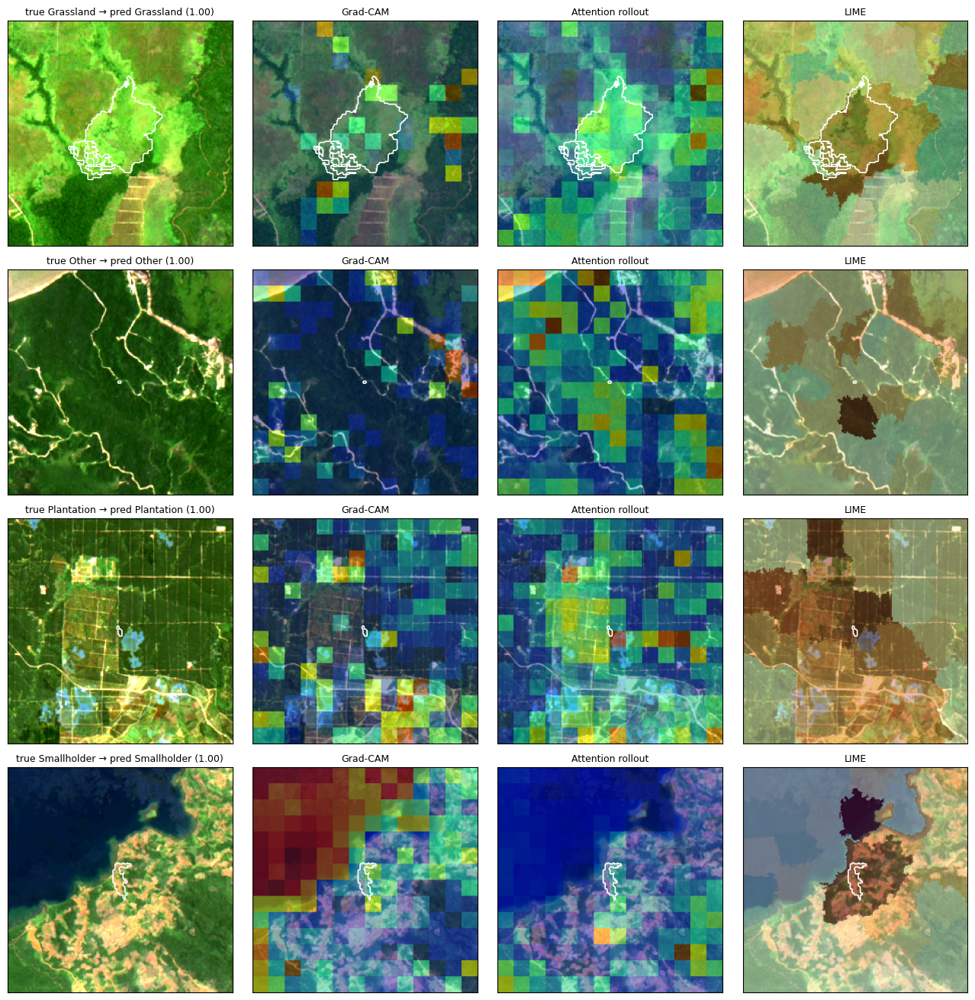

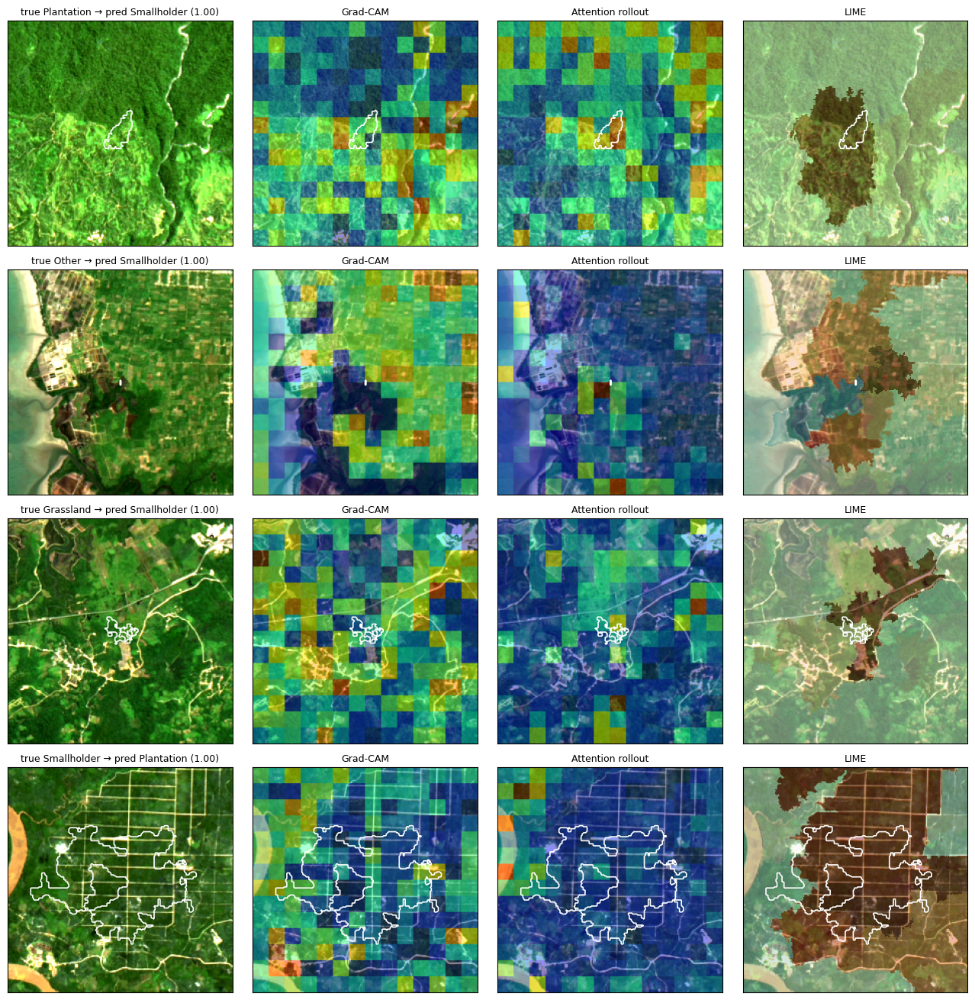

In [ ]:
def show_cases(kind, fname):
    sel = [(k, i) for k, i in cases if k == kind]
    if not sel:
        return
    fig, axes = plt.subplots(len(sel), 4, figsize=(13, 3.3 * len(sel)), squeeze=False)
    for row, (_, i) in enumerate(sel):
        img = VAL_IMGS[i]; g, r, lpix, segs = maps[i]; disp = stretch(img)
        m = loss_mask(man.example_path.values[VA_IDX][i])
        t, p = SHORT[inv[VAL_Y[i]]], SHORT[inv[VAL_PRED[i]]]
        panels = [("image (contrast-stretched)", None), ("Grad-CAM", up(g)), ("Attention rollout", up(r)), ("LIME", lpix)]
        for col, (title, h) in enumerate(panels):
            ax = axes[row, col]; ax.imshow(disp)
            if h is not None:
                ax.imshow(np.clip(h, 0, None) if title != "LIME" else h, cmap="jet" if title != "LIME" else "RdBu_r",
                          alpha=0.45, vmin=None if title != "LIME" else -np.abs(h).max(), vmax=None if title != "LIME" else np.abs(h).max())
            if m is not None:
                ax.contour(m, levels=[0.5], colors="white", linewidths=1.2)
            ax.set_xticks([]); ax.set_yticks([])
            ax.set_title(f"true {t} → pred {p} ({VAL_P[i, VAL_PRED[i]]:.2f})" if col == 0 else title, fontsize=9)
    plt.tight_layout(); plt.savefig(OUT4 / fname, dpi=130); plt.show()

show_cases("correct", "xai_cases_correct.png")
show_cases("incorrect", "xai_cases_incorrect.png")

**How to read the figures:** white outline = forest-loss polygon. Grad-CAM / rollout: red = most important.
LIME: red = superpixels that **support** the predicted class, blue = superpixels that **argue against** it.

## 8. Summary

In [ ]:
print("=== STAGE 4 SUMMARY ===")
print("Model:", RUN_ID, "| val macro-F1", round(finals[RUN_ID]["val"]["macro_f1"], 4))
print("\nCost (ms/image):"); display(cost_df)
print("\nDeletion test:"); display(faith)
print("\nRandomisation test (Spearman, lower = explanation depends more on learned weights):"); display(rand_summary)
if len(focus_df):
    print("\nLoss-region focus ratio (median):", focus_df[["Grad-CAM", "Attention rollout"]].median().round(2).to_dict(),
          "| median polygon area share:", round(focus_df.area_share.median(), 3))
print("\nCases:"); display(case_df.round(3))

=== STAGE 4 SUMMARY ===
Model: S3-VIT-FINAL-s43 | val macro-F1 0.7747

Cost (ms/image):


,ms per image
Grad-CAM,27.1
Attention rollout,10.3
"LIME (1,000 samples)",6551.4
Prediction only,11.8



Deletion test:


,n images,AUC mean (lower = better),AUC sd,prob. after hiding 10%,prob. after hiding 20%
Grad-CAM,100.0,0.739,0.345,0.805,0.756
Attention rollout,100.0,0.823,0.280,0.864,0.835
LIME,30.0,0.636,0.314,0.826,0.658
Random,100.0,0.901,0.178,0.926,0.913
Random (LIME subset),30.0,0.888,0.176,0.920,0.912



Randomisation test (Spearman, lower = explanation depends more on learned weights):


,mean,std,count
Grad-CAM,0.015,0.270,18.0
Attention rollout,0.972,0.022,20.0
LIME,-0.132,0.254,9.0



Loss-region focus ratio (median): {'Grad-CAM': 0.94, 'Attention rollout': 1.51} | median polygon area share: 0.008

Cases:


,case,event,fine label,true,predicted,p(pred),p(true),p(pred) after hiding top-20% Grad-CAM,p(pred) after hiding random 20%,p(true) after hiding top-20% Grad-CAM,new prediction,loss area px2,longitude,year
0,correct,-1.8963258594704733_114.9951928884913,Grassland shrubland,Grassland,Grassland,1.000,1.000,1.000,1.000,1.000,Grassland,9356.035,114.995,2016
1,correct,3.5529310810084938_117.7844949394277,Other,Other,Other,1.000,1.000,0.999,1.000,0.999,Other,7.995,117.784,2005
2,correct,-2.112326775683876_111.23824160102018,Oil palm plantation,Plantation,Plantation,0.999,0.999,0.999,0.999,0.999,Plantation,67.947,111.238,2006
3,correct,-2.879126286209593_121.5272293981342,Small-scale agriculture,Smallholder,Smallholder,0.999,0.999,0.999,0.999,0.999,Smallholder,679.907,121.527,2011
4,incorrect,-2.920259785670713_101.66928003449416,Oil palm plantation,Plantation,Smallholder,0.997,0.001,0.995,0.996,0.002,Smallholder,1181.629,101.669,2006
5,incorrect,-4.97765726300929_122.39460406176488,Fish pond,Other,Smallholder,0.998,0.001,0.993,0.998,0.004,Smallholder,15.989,122.395,2003
6,incorrect,2.021788868501325_117.6594796679378,Grassland shrubland,Grassland,Smallholder,0.999,0.001,0.998,0.998,0.001,Smallholder,699.533,117.659,2015
7,incorrect,-1.097476095228766_114.90394830161316,Small-scale mixed plantation,Smallholder,Plantation,0.998,0.002,0.998,0.998,0.002,Plantation,19614.728,114.904,2002


In [ ]:
# --- definitions normally created in §4, §6 and §7 (needed after a runtime restart) ---
inv = {v: k for k, v in CLS2ID.items()}
rng = np.random.default_rng(SEED)
FRACS = [0.0, 0.05, 0.10, 0.20, 0.30, 0.50]

def hide_patches(img_u8, order, frac):
    k = int(round(frac * GRID * GRID)); out = img_u8.astype(np.float32).copy()
    for p in order[:k]:
        r, c = divmod(int(p), GRID); out[r * 16:(r + 1) * 16, c * 16:(c + 1) * 16] = MEAN_U8
    return out.astype(np.uint8)

ZIP = next((z for z in (BASE / "data" / "ForestNetDataset.zip", Path("/content/local/ForestNetDataset.zip")) if z.exists()), None)
ZF = zipfile.ZipFile(ZIP) if ZIP else None
PREFIX = next(n for n in ZF.namelist() if n.endswith("train.csv"))[:-len("train.csv")] if ZF else None

def loss_mask(example_path, size=IMG, orig=332):
    if ZF is None:
        return None
    try:
        poly = pickle.loads(ZF.read(f"{PREFIX}{example_path}/forest_loss_region.pkl"))
    except KeyError:
        return None
    yy, xx = np.mgrid[0:size, 0:size]; pts = np.c_[xx.ravel() + 0.5, yy.ravel() + 0.5] * (orig / size)
    m = np.zeros(size * size, bool)
    for g in getattr(poly, "geoms", [poly]):
        m |= MplPath(np.asarray(g.exterior.coords)).contains_points(pts)
    return m.reshape(size, size)
# --- end of definitions ---

,case,fine label,true,pred,p(pred),margin,margin GradCAM 20%,flip GradCAM 20%,margin LIME 20%,flip LIME 20%,margin random 20%,margin GradCAM 40%,flip GradCAM 40%,margin LIME 40%,flip LIME 40%,margin random 40%
0,correct,Grassland shrubland,Grassland,Grassland,1.00,8.36,5.43,Grassland,6.35,Grassland,8.29,4.38,Grassland,6.03,Grassland,6.90
1,correct,Logging,Other,Other,1.00,6.49,-4.11,Plantation,1.72,Other,4.59,-7.35,Plantation,-3.24,Plantation,-2.60
2,correct,Other large-scale plantations,Plantation,Plantation,0.99,5.32,4.48,Plantation,5.23,Plantation,4.58,4.98,Plantation,5.90,Plantation,4.64
3,correct,Small-scale agriculture,Smallholder,Smallholder,1.00,6.22,6.14,Smallholder,1.72,Smallholder,6.92,6.30,Smallholder,0.43,Smallholder,6.09
4,incorrect,Oil palm plantation,Plantation,Smallholder,0.84,1.73,2.60,Smallholder,-3.66,Plantation,-0.36,3.27,Smallholder,-5.37,Plantation,1.57
5,incorrect,Mining,Other,Smallholder,0.97,3.90,-0.72,Other,-6.33,Other,2.35,-0.04,Other,-7.32,Other,2.50
6,incorrect,Grassland shrubland,Grassland,Smallholder,0.98,4.15,-4.13,Plantation,-3.47,Plantation,1.91,-3.98,Plantation,-4.25,Plantation,-0.36
7,incorrect,Small-scale agriculture,Smallholder,Plantation,0.94,3.37,0.33,Plantation,6.58,Plantation,2.66,-1.30,Smallholder,6.77,Plantation,3.95


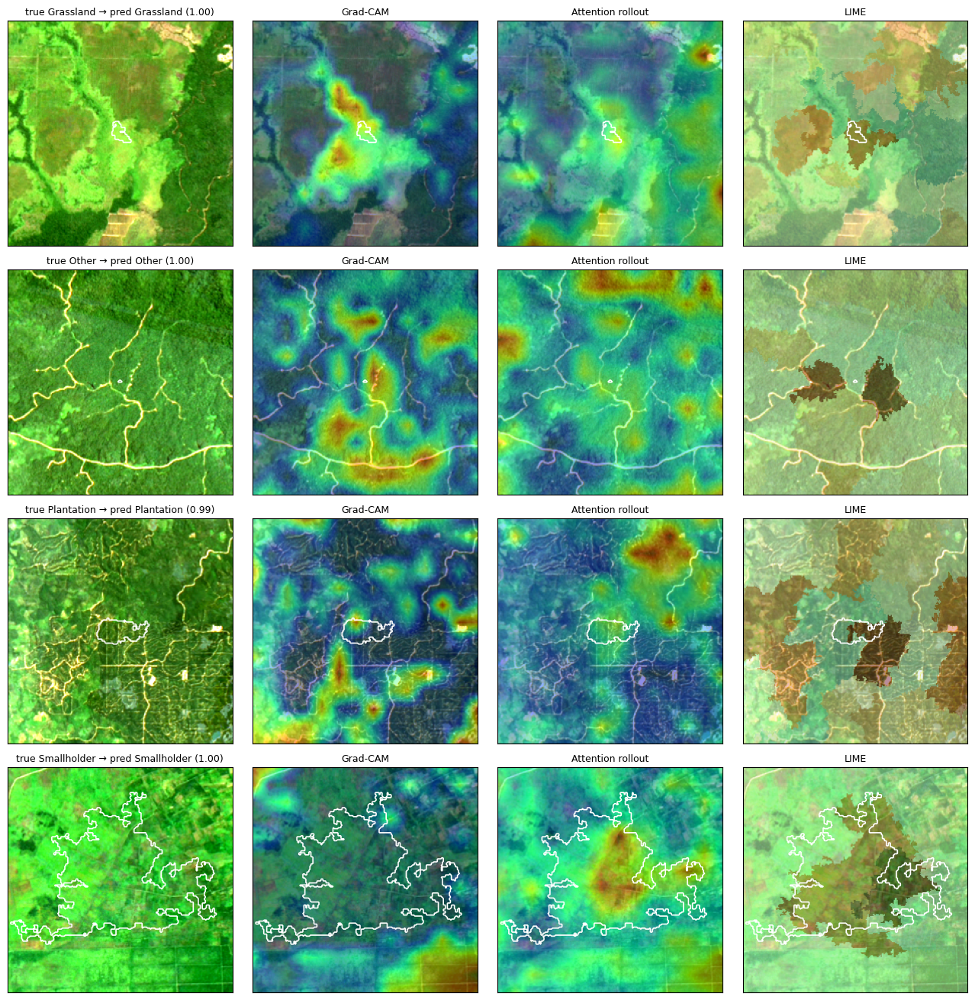

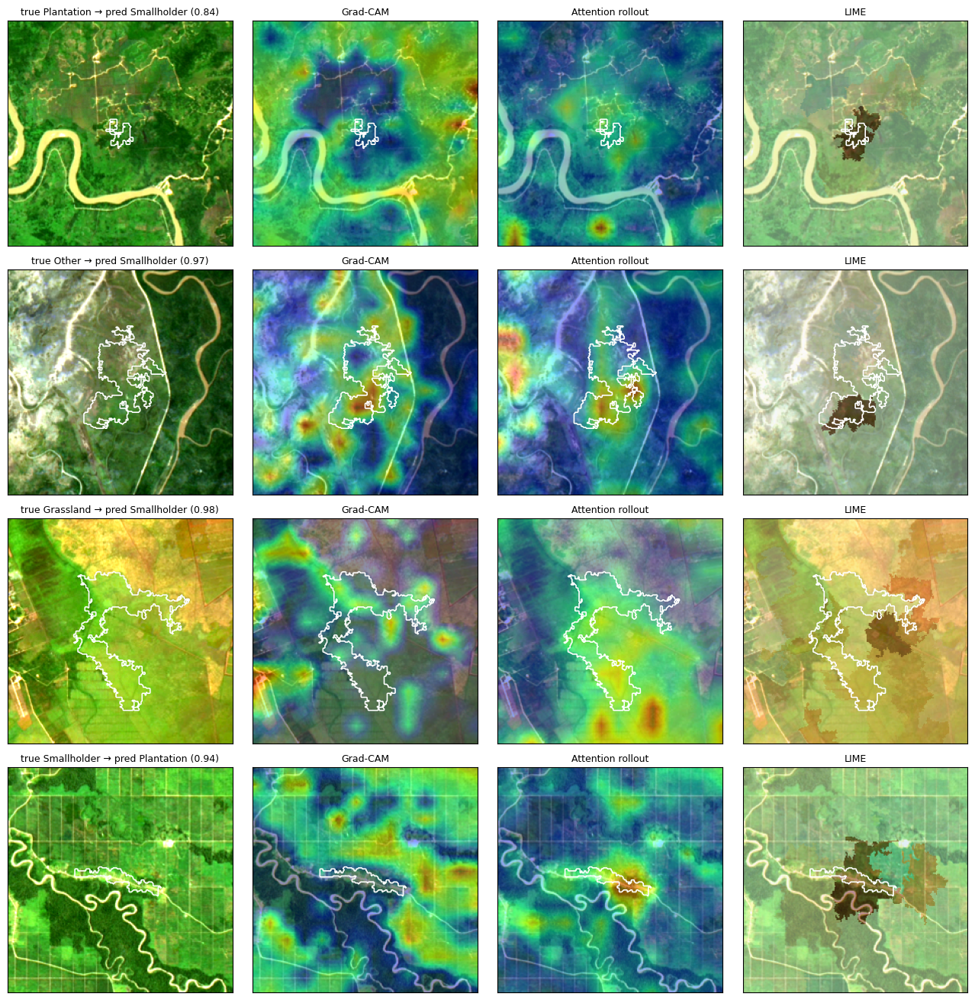

Expected calibration error (ECE): 0.132 | mean confidence 0.939 vs accuracy 0.814
Predictions with confidence > 0.99: 58.4% — their accuracy: 0.913
Wrong predictions with confidence > 0.99: 24 of 88 errors


In [ ]:
# 7b — Representative cases + occlusion measured on the logit margin, and calibration check
import scipy.ndimage as ndi

@torch.no_grad()
def logits_of(imgs_u8, m=None, bs=64):
    m = m or model
    return np.concatenate([m(to_tensor(imgs_u8[b:b + bs])).float().cpu().numpy() for b in range(0, len(imgs_u8), bs)])

def margin(lg, c):
    other = np.delete(lg, c, axis=-1)
    return lg[..., c] - other.max(-1)

conf = VAL_P.max(1); cases2 = []
for c in range(len(CLASSES)):
    ok = np.where((VAL_Y == c) & (VAL_PRED == c))[0]
    if len(ok): cases2.append(("correct", ok[np.argsort(conf[ok])[len(ok) // 2]]))
for t, ps in [("Plantation", ["Smallholder agriculture"]), ("Other", ["Smallholder agriculture", "Grassland shrubland"]),
              ("Grassland shrubland", ["Smallholder agriculture"]), ("Smallholder agriculture", ["Plantation"])]:
    bad = np.where((VAL_Y == CLS2ID[t]) & np.isin(VAL_PRED, [CLS2ID[p] for p in ps]))[0]
    if len(bad): cases2.append(("incorrect", bad[np.argsort(conf[bad])[len(bad) // 2]]))

rows, maps2 = [], {}
for kind, i in cases2:
    img, tgt, true = VAL_IMGS[i], VAL_PRED[i], VAL_Y[i]
    g, r = gradcam(img[None])[0], rollout(img[None])[0]
    l, lpix, segs = lime_explain(img, tgt)
    maps2[i] = (g, r, lpix)
    lg0 = logits_of(img[None])[0]
    row = {"case": kind, "fine label": man.label.values[VA_IDX][i], "true": SHORT[inv[true]], "pred": SHORT[inv[tgt]],
           "p(pred)": VAL_P[i, tgt], "margin": margin(lg0, tgt)}
    for frac in (0.2, 0.4):
        for name, imp in [("GradCAM", g), ("LIME", l)]:
            lg = logits_of(hide_patches(img, np.argsort(-imp.ravel()), frac)[None])[0]
            row[f"margin {name} {int(frac*100)}%"] = margin(lg, tgt); row[f"flip {name} {int(frac*100)}%"] = SHORT[inv[lg.argmax()]]
        rl = logits_of(np.stack([hide_patches(img, rng.permutation(GRID * GRID), frac) for _ in range(5)]))
        row[f"margin random {int(frac*100)}%"] = margin(rl, tgt).mean()
    rows.append(row)
case2_df = pd.DataFrame(rows); display(case2_df.round(2)); case2_df.to_csv(OUT4 / "xai_cases_representative.csv", index=False)

def smooth(m14): return np.clip(ndi.zoom(m14, 16, order=1), 0, None)
for kind in ("correct", "incorrect"):
    sel = [i for k, i in cases2 if k == kind]
    fig, axes = plt.subplots(len(sel), 4, figsize=(13, 3.3 * len(sel)), squeeze=False)
    for rr, i in enumerate(sel):
        img = VAL_IMGS[i]; g, r, lpix = maps2[i]; m = loss_mask(man.example_path.values[VA_IDX][i])
        for cc, (title, h, cmap) in enumerate([("image", None, None), ("Grad-CAM", smooth(g), "jet"),
                                               ("Attention rollout", smooth(r), "jet"), ("LIME", lpix, "RdBu_r")]):
            ax = axes[rr, cc]; ax.imshow(stretch(img))
            if h is not None:
                v = np.abs(h).max() if cmap == "RdBu_r" else None
                ax.imshow(h, cmap=cmap, alpha=0.45, vmin=-v if v else None, vmax=v)
            if m is not None: ax.contour(m, levels=[0.5], colors="white", linewidths=1.2)
            ax.set_xticks([]); ax.set_yticks([])
            ax.set_title(f"true {SHORT[inv[VAL_Y[i]]]} → pred {SHORT[inv[VAL_PRED[i]]]} ({VAL_P[i, VAL_PRED[i]]:.2f})" if cc == 0 else title, fontsize=9)
    plt.tight_layout(); plt.savefig(OUT4 / f"xai_cases_representative_{kind}.png", dpi=130); plt.show()

# Calibration: is the model overconfident?
acc = VAL_PRED == VAL_Y; bins = np.linspace(0, 1, 11); ece = 0
for lo, hi in zip(bins[:-1], bins[1:]):
    s = (conf > lo) & (conf <= hi)
    if s.any(): ece += s.mean() * abs(acc[s].mean() - conf[s].mean())
print(f"Expected calibration error (ECE): {ece:.3f} | mean confidence {conf.mean():.3f} vs accuracy {acc.mean():.3f}")
print(f"Predictions with confidence > 0.99: {(conf > 0.99).mean():.1%} — their accuracy: {acc[conf > 0.99].mean():.3f}")
print(f"Wrong predictions with confidence > 0.99: {((conf > 0.99) & ~acc).sum()} of {(~acc).sum()} errors")